In [1]:
from typing import cast

# pytorch
import torch
from torch_geometric.utils import degree, homophily
from torch_geometric.data import Data
from dataset import CLASS_NAMES, add_stratified_masks, load_facebook_data

# plotting
import seaborn as sbn
#import matplotlib.pyplot as plt
from matplotlib import pyplot as plt

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### Data Pipeline
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Constants

In [2]:
# NOTE: placeholder cell for definition of constants

#### Data Inspection

In [3]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()

# inspect data properties
print(f'Dataset: {dataset}')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

data = dataset[0]  # get first graph object

print('\nGraph data format:')
print(data)

Dataset: FacebookPagePage()
Number of graphs: 1
Number of features: 128
Number of classes: 4

Graph data format:
Data(x=[22470, 128], edge_index=[2, 342004], y=[22470])


Basic EDA

In [13]:
# inspect labels
classes, counts = torch.unique(data.y, return_counts=True)

label_count = counts.sum().item()
node_count: int | None = data.num_nodes

if node_count is None:
    raise ValueError("Graph does not define the number of nodes.")
print(f'\nNum missing labels: {node_count - label_count}\n')

print('Class distribution:')
for cls, count in zip(classes.tolist(), counts.tolist()):
    print(
        f"  {CLASS_NAMES[cls]:10}: "
        f"{count:5} "
        f"({count / node_count:.2%})"
    )

# label_count = counts.sum().item()
# node_count: int | None = data.num_nodes
#
# if node_count is None:
#     raise ValueError("Graph does not define the number of nodes.")
# print(f'\nNum missing labels: {node_count - label_count}')


Num missing labels: 0

Class distribution:
  tvshow    :  6495 (28.91%)
  government:  6880 (30.62%)
  company   :  5768 (25.67%)
  politician:  3327 (14.81%)


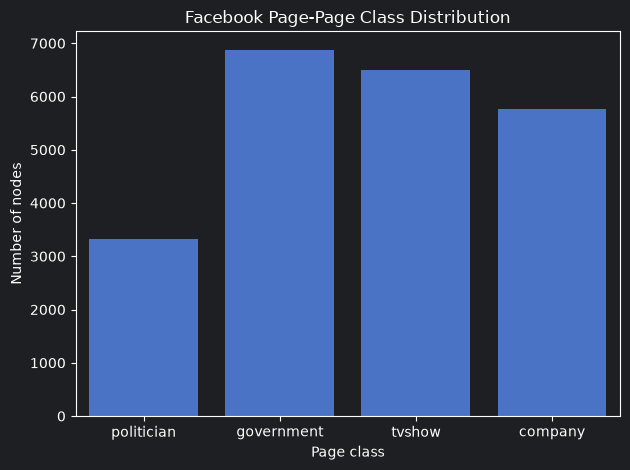

In [5]:
# get class labels for plot
class_labels = [CLASS_NAMES[label] for label in data.y.tolist()]

plt.figure()
ax_class_counts = sbn.countplot(x=class_labels)

plt.xlabel("Page class")
plt.ylabel("Number of nodes")
plt.title("Facebook Page-Page Class Distribution")

plt.tight_layout()
fig_class_counts = ax_class_counts.get_figure()


Degree min:    1
Degree median: 7
Degree mean:   15.22
Degree max:    709


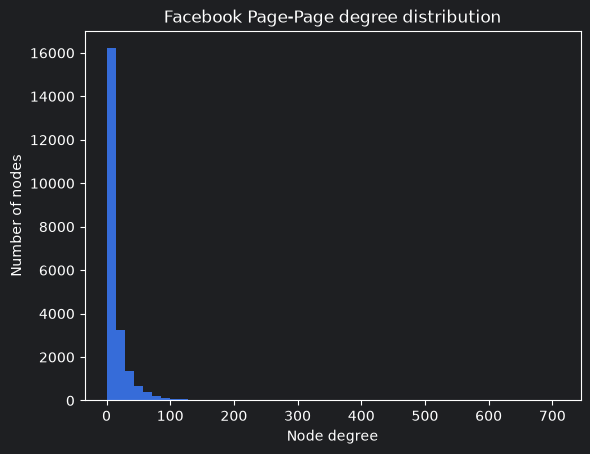

In [6]:
# inspect degrees
deg = degree(
    data.edge_index[0],
    num_nodes=data.num_nodes,
)

print()
print(f"Degree min:    {deg.min().item():.0f}")
print(f"Degree median: {deg.median().item():.0f}")
print(f"Degree mean:   {deg.mean().item():.2f}")
print(f"Degree max:    {deg.max().item():.0f}")

plt.hist(deg.cpu(), bins=50)
plt.xlabel("Node degree")
plt.ylabel("Number of nodes")
plt.title("Facebook Page-Page degree distribution")
plt.show()

In [7]:
# inspect features
print()
print(f"Feature min:   {data.x.min().item():.4f}")
print(f"Feature max:   {data.x.max().item():.4f}")
print(f"Feature mean:  {data.x.mean().item():.4f}")
print(f"Feature std:   {data.x.std().item():.4f}")
print(f"Zero fraction: {(data.x == 0).float().mean().item():.4f}")


Feature min:   -2.0376
Feature max:   3.0020
Feature mean:  0.0103
Feature std:   0.2551
Zero fraction: 0.0000


In [8]:
# inspect graph structure
print()
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')


Has isolated nodes: False
Has self-loops: True
Is undirected: True


In [9]:
# inspect homophily (i.e. how likely nodes with the same label are near each other in a graph)
print()
print(
    f"Edge homophily: "
    f"{homophily(data.edge_index, data.y, method='edge'):.4f}"
)


Edge homophily: 0.8854


#### Data Splits

Provisional Data Splits for Feasibility Review

In [10]:
# create reproducible stratified train/validation/test splits
data = add_stratified_masks(
    cast(Data, data),
    train_pct=60,
    val_pct=20,
    test_pct=20,
    seed=808,
)

# verify the split masks are non-overlapping
assert not (data.train_mask & data.val_mask).any().item()
assert not (data.train_mask & data.test_mask).any().item()
assert not (data.val_mask & data.test_mask).any().item()
# verify the split masks cover the complete data set
assert (data.train_mask | data.val_mask | data.test_mask).all().item()

Inspect split sizes and class distributions

In [15]:
labels = data.y
if not isinstance(labels, torch.Tensor):
    raise TypeError("Graph labels must be stored as a PyTorch Tensor.")

splits = {
    "Train": data.train_mask,
    "Validation": data.val_mask,
    "Test": data.test_mask,
}

for split_name, mask in splits.items():
    split_size = mask.sum().item() # total size of given split

    # get label distribution for split
    classes, counts = torch.unique(
        labels[mask],
        return_counts=True,
    )

    # print the distribution of classes in this split
    print(f"\n{split_name}: {split_size} nodes")

    for cls, count in zip(classes.tolist(), counts.tolist()):
        print(
            f"  {CLASS_NAMES[cls]:10}: "
            f"{count:5} "
            f"({count / split_size:.2%})"
        )


Train: 13482 nodes
  tvshow    :  3897 (28.91%)
  government:  4128 (30.62%)
  company   :  3461 (25.67%)
  politician:  1996 (14.80%)

Validation: 4494 nodes
  tvshow    :  1299 (28.91%)
  government:  1376 (30.62%)
  company   :  1153 (25.66%)
  politician:   666 (14.82%)

Test: 4494 nodes
  tvshow    :  1299 (28.91%)
  government:  1376 (30.62%)
  company   :  1154 (25.68%)
  politician:   665 (14.80%)
